<a href="https://colab.research.google.com/github/RebeccaDai615/Google-Street-View-Panorama-Image-Crawler/blob/main/google_street_view_crawler.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Google Street View Panorama Image Crawler
This Notebook is used to download panoramic images from Google Street View.
Function Description
Read geographical coordinates from CSV files
Obtain Google Street View panorama IDs for corresponding locations
Download and stitch high-resolution panoramic images
Support multi-threaded download acceleration
Automatic retry mechanism



## 1. Install the necessary dependency packages

Install dependency packages if you run in your local environment：


In [ ]:
# # Install dependency packages if you run in your local environment

# ! pip install numpy==1.17.3
# ! pip install opencv-python==4.10.0.84
# ! pip install Pillow==9.5.0
# ! pip install requests==2.18.4
# ! pip install urllib3==1.22

# print("\nAll dependent packages have been installed！")


In [ ]:
## connect to google drive
from google.colab import drive
drive.mount('/content/drive/')
print('conecting finish')

Mounted at /content/drive/
conecting finish


## 2. Import the required libraries


In [ ]:
import csv
import os
import random
import threading
import time
import warnings
import re
from itertools import islice
from datetime import datetime
from io import BytesIO

import cv2
import numpy as np
import requests
from PIL import Image

warnings.filterwarnings('ignore')

print("Library imported successfully！")


Library imported successfully！


## 3. google_pan definitions

In [ ]:
def _panoids_url(lat, lon):
    """
    Builds the URL of the script on Google's servers that returns the closest
    panoramas (ids) to a give GPS coordinate.
    """
    url = "https://maps.googleapis.com/maps/api/js/GeoPhotoService.SingleImageSearch?pb=!1m5!1sapiv3!5sUS!11m2!1m1!1b0!2m4!1m2!3d{0:}!4d{1:}!2d50!3m10!2m2!1sen!2sGB!9m1!1e2!11m4!1m3!1e2!2b1!3e2!4m10!1e1!1e2!1e3!1e4!1e8!1e6!5m1!1e2!6m1!1e2&callback=_xdc_._v2mub5"
    return url.format(lat, lon)


def _panoids_data(lat, lon, proxies=None):
    """
    Gets the response of the script on Google's servers that returns the
    closest panoramas (ids) to a give GPS coordinate.
    """
    url = _panoids_url(lat, lon)
    return requests.get(url, proxies=None)


def panoids(lat, lon, closest=False, disp=False, proxies=None):
    """
    Gets the closest panoramas (ids) to the GPS coordinates.
    If the 'closest' boolean parameter is set to true, only the closest panorama
    will be gotten (at all the available dates)
    """

    resp = _panoids_data(lat, lon)

    # Get all the panorama ids and coordinates
    pans = re.findall('\[[0-9]+,"(.+?)"\].+?\[\[null,null,(-?[0-9]+.[0-9]+),(-?[0-9]+.[0-9]+)', resp.text)
    pans = [{
        "panoid": p[0],
        "lat": float(p[1]),
        "lon": float(p[2])} for p in pans]  # Convert to floats

    # Remove duplicate panoramas
    pans = [p for i, p in enumerate(pans) if p not in pans[:i]]

    if disp:
        for pan in pans:
            print(pan)

    # Get all the dates
    dates = re.findall('([0-9]?[0-9]?[0-9])?,?\[(20[0-9][0-9]),([0-9]+)\]', resp.text)
    dates = [list(d)[1:] for d in dates]  # Convert to lists and drop the index

    if len(dates) > 0:
        # Convert all values to integers
        dates = [[int(v) for v in d] for d in dates]

        # Make sure the month value is between 1-12
        dates = [d for d in dates if d[1] <= 12 and d[1] >= 1]

        # The last date belongs to the first panorama
        year, month = dates.pop(-1)
        pans[0].update({'year': year, "month": month})

        # The dates then apply in reverse order to the bottom panoramas
        dates.reverse()
        for i, (year, month) in enumerate(dates):
            pans[-1 - i].update({'year': year, "month": month})

    # Sort the pans array
    def func(x):
        if 'year' in x:
            return datetime(year=x['year'], month=x['month'], day=1)
        else:
            return datetime(year=3000, month=1, day=1)

    pans.sort(key=func)

    if closest:
        return [pans[i] for i in range(len(dates))]
    else:
        return pans


print("The google_pan module function has been loaded successfully.！")


The google_pan module function has been loaded successfully.！


In [ ]:
# File path configuration
filepath = '/content/drive/MyDrive/python skill /GSVIpan/location-2 03.14.36.csv'  # Input coordinate file， currently, you can download this "location.csv file provided in the GSVIpan folder for this download, you need to correct this file path and make sure its align with your data folder name"
output = '/content/drive/MyDrive/SVI/GPan/pano_shift72'  # Output folder
filename = os.path.basename(output)

# Crawling range settings (ID range)
id_low = 0   # start ID（not included）
id_high = 115 # end ID（not included）

# Proxy Settings (If you need to use a proxy, please configure it here), currently, we can keep this unchanged
proxies = {
    # 'http': 'http://your_proxy:port',
    # 'https': 'https://your_proxy:port',
}

# HTTP Request header
headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/106.0.0.0 Safari/537.36'
}

# Number of retries
max_p = 5

print(f"Configuration completed！")
print(f"Input file: {filepath}")
print(f"Output file: {output}")
print(f"Download range: ID {id_low} to {id_high}")


Configuration completed！
Input file: /content/drive/MyDrive/python skill /GSVIpan/location-2 03.14.36.csv
Output file: /content/drive/MyDrive/SVI/GPan/pano_shift72
Download range: ID 0 to 115


## 5. Image processing function




In [ ]:
def jigsaw(imgs, direction="horizontal", gap=0):
    """
    Image stitching function
    """
    imgs = [Image.fromarray(img) for img in imgs]
    w, h = imgs[0].size
    if direction == "horizontal":
        result = Image.new(imgs[0].mode, ((w+gap)*len(imgs)-gap, h))
        for i, img in enumerate(imgs):
            result.paste(img, box=((w+gap)*i, 0))
    elif direction == "vertical":
        result = Image.new(imgs[0].mode, (w, (h+gap)*len(imgs)-gap))
        for i, img in enumerate(imgs):
            result.paste(img, box=(0, (h+gap)*i))
    else:
        raise ValueError("The direction parameter has only two options: horizontal and vertical")
    return np.array(result)


def from_url_get_img(url1):
    """
    Download images from a URL and convert them into numpy arrays
    """
    try:
        r1_bytes = requests.get(url1, verify=False, headers=headers, proxies=proxies).content
        # Image decoding and splicing
        img_buffer_numpy_1 = np.frombuffer(r1_bytes, dtype=np.uint8)
        img_numpy_1 = cv2.imdecode(img_buffer_numpy_1, 1)
        return img_numpy_1
    except:
        return None


def Getpanoid(lat, lon):
    """
    Obtain a panoramic image based on longitude and latitude ID
    """
    try:
        pan_list = panoids(lat, lon)
        current_pan = None
        for pan in pan_list:
            if len(pan) == 5:
                current_pan = pan
        return current_pan['panoid']
    except:
        print('Get panoid fails!')
        return None


print("Image processing function loaded successfully！")


Image processing function loaded successfully！


## 6. Image block download function (multi-threading)

These functions are used to download 各个部分 of the panoramic image in parallel (4 rows x 8 columns = 32 image blocks)


In [ ]:
# Global variables are used to store image blocks.
block_list_0 = {}
block_list_1 = {}
block_list_2 = {}
block_list_3 = {}


# General function: Download image blocks at specified positions
def get_block(panoid, x, y, block_list, key):
    """
    Download the image tile at the specified coordinates
    """
    flag = False
    num = 0
    while (not flag) and num < max_p:
        url = f'https://streetviewpixels-pa.googleapis.com/v1/tile?cb_client=maps_sv.tactile&panoid={panoid}&x={x}&y={y}&zoom=3'
        img_numpy = from_url_get_img(url)
        block_list[key] = img_numpy
        if isinstance(img_numpy, np.ndarray):
            flag = True
        num += 1


# The function for downloading 8 image blocks in row 0
def get_block_0_1(panoid):
    get_block(panoid, 7, 0, block_list_0, 1)

def get_block_0_2(panoid):
    get_block(panoid, 0, 0, block_list_0, 2)

def get_block_0_3(panoid):
    get_block(panoid, 1, 0, block_list_0, 3)

def get_block_0_4(panoid):
    get_block(panoid, 2, 0, block_list_0, 4)

def get_block_0_5(panoid):
    get_block(panoid, 3, 0, block_list_0, 5)

def get_block_0_6(panoid):
    get_block(panoid, 4, 0, block_list_0, 6)

def get_block_0_7(panoid):
    get_block(panoid, 5, 0, block_list_0, 7)

def get_block_0_8(panoid):
    get_block(panoid, 6, 0, block_list_0, 8)


# The download function for the 8 image blocks in the first line
def get_block_1_1(panoid):
    get_block(panoid, 7, 1, block_list_1, 1)

def get_block_1_2(panoid):
    get_block(panoid, 0, 1, block_list_1, 2)

def get_block_1_3(panoid):
    get_block(panoid, 1, 1, block_list_1, 3)

def get_block_1_4(panoid):
    get_block(panoid, 2, 1, block_list_1, 4)

def get_block_1_5(panoid):
    get_block(panoid, 3, 1, block_list_1, 5)

def get_block_1_6(panoid):
    get_block(panoid, 4, 1, block_list_1, 6)

def get_block_1_7(panoid):
    get_block(panoid, 5, 1, block_list_1, 7)

def get_block_1_8(panoid):
    get_block(panoid, 6, 1, block_list_1, 8)


# The function for downloading 8 image blocks in the 2nd line
def get_block_2_1(panoid):
    get_block(panoid, 7, 2, block_list_2, 1)

def get_block_2_2(panoid):
    get_block(panoid, 0, 2, block_list_2, 2)

def get_block_2_3(panoid):
    get_block(panoid, 1, 2, block_list_2, 3)

def get_block_2_4(panoid):
    get_block(panoid, 2, 2, block_list_2, 4)

def get_block_2_5(panoid):
    get_block(panoid, 3, 2, block_list_2, 5)

def get_block_2_6(panoid):
    get_block(panoid, 4, 2, block_list_2, 6)

def get_block_2_7(panoid):
    get_block(panoid, 5, 2, block_list_2, 7)

def get_block_2_8(panoid):
    get_block(panoid, 6, 2, block_list_2, 8)


# The function for downloading 8 image blocks in the 3rd line
def get_block_3_1(panoid):
    get_block(panoid, 7, 3, block_list_3, 1)

def get_block_3_2(panoid):
    get_block(panoid, 0, 3, block_list_3, 2)

def get_block_3_3(panoid):
    get_block(panoid, 1, 3, block_list_3, 3)

def get_block_3_4(panoid):
    get_block(panoid, 2, 3, block_list_3, 4)

def get_block_3_5(panoid):
    get_block(panoid, 3, 3, block_list_3, 5)

def get_block_3_6(panoid):
    get_block(panoid, 4, 3, block_list_3, 6)

def get_block_3_7(panoid):
    get_block(panoid, 5, 3, block_list_3, 7)

def get_block_3_8(panoid):
    get_block(panoid, 6, 3, block_list_3, 8)


print("The image block download function has been loaded！")


The image block download function has been loaded！


In [ ]:
def save_pic_12(panoid, id, lon, lat):
    """
    The core function for downloading and stitching panoramic images
    Download 4x8 image patches in parallel using 32 threads
    """
    global block_list_0, block_list_1, block_list_2, block_list_3

    try:
        # Create 32 threads
        thread1 = threading.Thread(name='t1', target=get_block_0_1, args=(panoid,))
        thread2 = threading.Thread(name='t2', target=get_block_0_2, args=(panoid,))
        thread3 = threading.Thread(name='t3', target=get_block_0_3, args=(panoid,))
        thread4 = threading.Thread(name='t4', target=get_block_0_4, args=(panoid,))
        thread5 = threading.Thread(name='t5', target=get_block_0_5, args=(panoid,))
        thread6 = threading.Thread(name='t6', target=get_block_0_6, args=(panoid,))
        thread7 = threading.Thread(name='t7', target=get_block_0_7, args=(panoid,))
        thread8 = threading.Thread(name='t8', target=get_block_0_8, args=(panoid,))

        thread9 = threading.Thread(name='t9', target=get_block_1_1, args=(panoid,))
        thread10 = threading.Thread(name='t10', target=get_block_1_2, args=(panoid,))
        thread11 = threading.Thread(name='t11', target=get_block_1_3, args=(panoid,))
        thread12 = threading.Thread(name='t12', target=get_block_1_4, args=(panoid,))
        thread13 = threading.Thread(name='t13', target=get_block_1_5, args=(panoid,))
        thread14 = threading.Thread(name='t14', target=get_block_1_6, args=(panoid,))
        thread15 = threading.Thread(name='t15', target=get_block_1_7, args=(panoid,))
        thread16 = threading.Thread(name='t16', target=get_block_1_8, args=(panoid,))

        thread17 = threading.Thread(name='t17', target=get_block_2_1, args=(panoid,))
        thread18 = threading.Thread(name='t18', target=get_block_2_2, args=(panoid,))
        thread19 = threading.Thread(name='t19', target=get_block_2_3, args=(panoid,))
        thread20 = threading.Thread(name='t20', target=get_block_2_4, args=(panoid,))
        thread21 = threading.Thread(name='t21', target=get_block_2_5, args=(panoid,))
        thread22 = threading.Thread(name='t22', target=get_block_2_6, args=(panoid,))
        thread23 = threading.Thread(name='t23', target=get_block_2_7, args=(panoid,))
        thread24 = threading.Thread(name='t24', target=get_block_2_8, args=(panoid,))

        thread25 = threading.Thread(name='t25', target=get_block_3_1, args=(panoid,))
        thread26 = threading.Thread(name='t26', target=get_block_3_2, args=(panoid,))
        thread27 = threading.Thread(name='t27', target=get_block_3_3, args=(panoid,))
        thread28 = threading.Thread(name='t28', target=get_block_3_4, args=(panoid,))
        thread29 = threading.Thread(name='t29', target=get_block_3_5, args=(panoid,))
        thread30 = threading.Thread(name='t30', target=get_block_3_6, args=(panoid,))
        thread31 = threading.Thread(name='t31', target=get_block_3_7, args=(panoid,))
        thread32 = threading.Thread(name='t32', target=get_block_3_8, args=(panoid,))

        threads = [thread1, thread2, thread3, thread4, thread5, thread6, thread7, thread8,
                   thread9, thread10, thread11, thread12, thread13, thread14, thread15, thread16,
                   thread17, thread18, thread19, thread20, thread21, thread22, thread23, thread24,
                   thread25, thread26, thread27, thread28, thread29, thread30, thread31, thread32]

        # start all threads
        for t in threads:
            t.start()

        # wait for all threads complete
        for t in threads:
            t.join()

        # Stitching images
        hor_nums = 8

        bar_0 = [block_list_0[i + 1] for i in range(hor_nums)]
        img_full_0 = jigsaw(bar_0)

        bar_1 = [block_list_1[i + 1] for i in range(hor_nums)]
        img_full_1 = jigsaw(bar_1)

        bar_2 = [block_list_2[i + 1] for i in range(hor_nums)]
        img_full_2 = jigsaw(bar_2)

        bar_3 = [block_list_3[i + 1] for i in range(hor_nums)]
        img_full_3 = jigsaw(bar_3)

        img_full = jigsaw([img_full_0, img_full_1, img_full_2, img_full_3], direction="vertical")

        # Save the image
        savepath = f"{output}/{id}_{lon}_{lat}.jpg"
        pic_name = f"{id}_{lon}_{lat}.jpg"

        cv2.imwrite(savepath, img_full)

        # Record information
        with open('./' + filename + '_info.txt', 'a') as f:
            f.write(pic_name + ',' + str(id) + ',' + str(lon) + ',' + str(lat) + '\n')

        print(savepath, ' saved！')

        # Clear global variables
        block_list_0 = {}
        block_list_1 = {}
        block_list_2 = {}
        block_list_3 = {}

    except Exception as e:
        print(f'{panoid}, {id} fail! Error: {e}')


print("Main function has been setup！")


Main function has been setup！


In [ ]:
def craw():
    """
    Main function
    Read coordinates from CSV and download panoramas
    """
    # Create the output directory
    if not os.path.exists(output):
        os.mkdir(output)
        print(f"creating output folder: {output}")

    # Get the list of crawled files
    has_craw = os.listdir(output)
    print(f"already have {len(has_craw)} # images")

    with open(filepath, encoding='utf-8') as f:
        reader = csv.reader(f, skipinitialspace=True)
        id = 0
        success_count = 0
        skip_count = 0
        fail_count = 0

        for row in islice(reader, 1, None):  # Skip the header row
            id += 1

            # Check if it is within the specified range
            if not (id > id_low and id < id_high):
                continue

            lens = len(row)
            lon = row[lens - 2]
            lat = row[lens - 1]

            # Determine whether the current point has been crawled
            out_name = f"{id}_{lon}_{lat}.jpg"
            if out_name in has_craw:
                print(f"{out_name} already have！")
                skip_count += 1
                continue

            # get panoid
            panoid = Getpanoid(lat, lon)
            if panoid is not None:
                # Random delay
                if random.random() < 0.1:
                    sleep_time = random.random() * 1
                    time.sleep(sleep_time)

                # Download street view images
                try:
                    save_pic_12(panoid, id, lon, lat)
                    success_count += 1
                except:
                    fail_count += 1
            else:
                print(f"ID {id}: cannot get panoid")
                fail_count += 1

    print("\n=== finished ===")
    print(f"siccess: {success_count}")
    print(f"skip: {skip_count}")
    print(f"fail: {fail_count}")


print("Main downloader is deployed！")


Main downloader is deployed！


## 9. Run the crawler

Ensure that the file path is correctly configured in Step 4

Set an appropriate range for id_low and id_high

Make sure the location.csv file exists and is in the correct format

The downloaded images will be saved in the output directory

The crawled information will be recorded in the out_info.txt file





Run the following cell to start crawling:

In [ ]:
# Start to download
print("Start to download Google Street View image...\n")
craw()


Start to download Google Street View image...

already have 0 # images
/content/drive/MyDrive/SVI/GPan/pano_shift72/1_114.2023406_22.3464788.jpg  saved！
/content/drive/MyDrive/SVI/GPan/pano_shift72/2_114.2026851_22.3465367.jpg  saved！
/content/drive/MyDrive/SVI/GPan/pano_shift72/3_114.2030226_22.346546.jpg  saved！
/content/drive/MyDrive/SVI/GPan/pano_shift72/4_114.2019875_22.3464264.jpg  saved！
/content/drive/MyDrive/SVI/GPan/pano_shift72/5_114.2040321_22.3463627.jpg  saved！
/content/drive/MyDrive/SVI/GPan/pano_shift72/6_114.2018435_22.3462117.jpg  saved！
/content/drive/MyDrive/SVI/GPan/pano_shift72/7_114.201917_22.34576538.jpg  saved！
/content/drive/MyDrive/SVI/GPan/pano_shift72/8_114.2021961_22.34541239.jpg  saved！
/content/drive/MyDrive/SVI/GPan/pano_shift72/9_114.2025565_22.34511758.jpg  saved！
/content/drive/MyDrive/SVI/GPan/pano_shift72/10_114.2026833_22.34468319.jpg  saved！
/content/drive/MyDrive/SVI/GPan/pano_shift72/11_114.2027903_22.34424276.jpg  saved！
/content/drive/MyDrive

## 10. iew the results

Run the cell below to view the downloaded images:


In [ ]:
# Check thd output folder
if os.path.exists(output):
    files = os.listdir(output)
    print(f"Have totally downloaded {len(files)} # images")
    print("\nFirst 10 images:")
    for i, file in enumerate(files[:10]):
        print(f"{i+1}. {file}")
else:
    print("output folder dose not exist")


Have totally downloaded 99 # images

First 10 images:
1. 1_114.2023406_22.3464788.jpg
2. 2_114.2026851_22.3465367.jpg
3. 3_114.2030226_22.346546.jpg
4. 4_114.2019875_22.3464264.jpg
5. 5_114.2040321_22.3463627.jpg
6. 6_114.2018435_22.3462117.jpg
7. 7_114.201917_22.34576538.jpg
8. 8_114.2021961_22.34541239.jpg
9. 9_114.2025565_22.34511758.jpg
10. 10_114.2026833_22.34468319.jpg


## 11. Display an example image (optional)


Visualizing image: 1_114.2023406_22.3464788.jpg


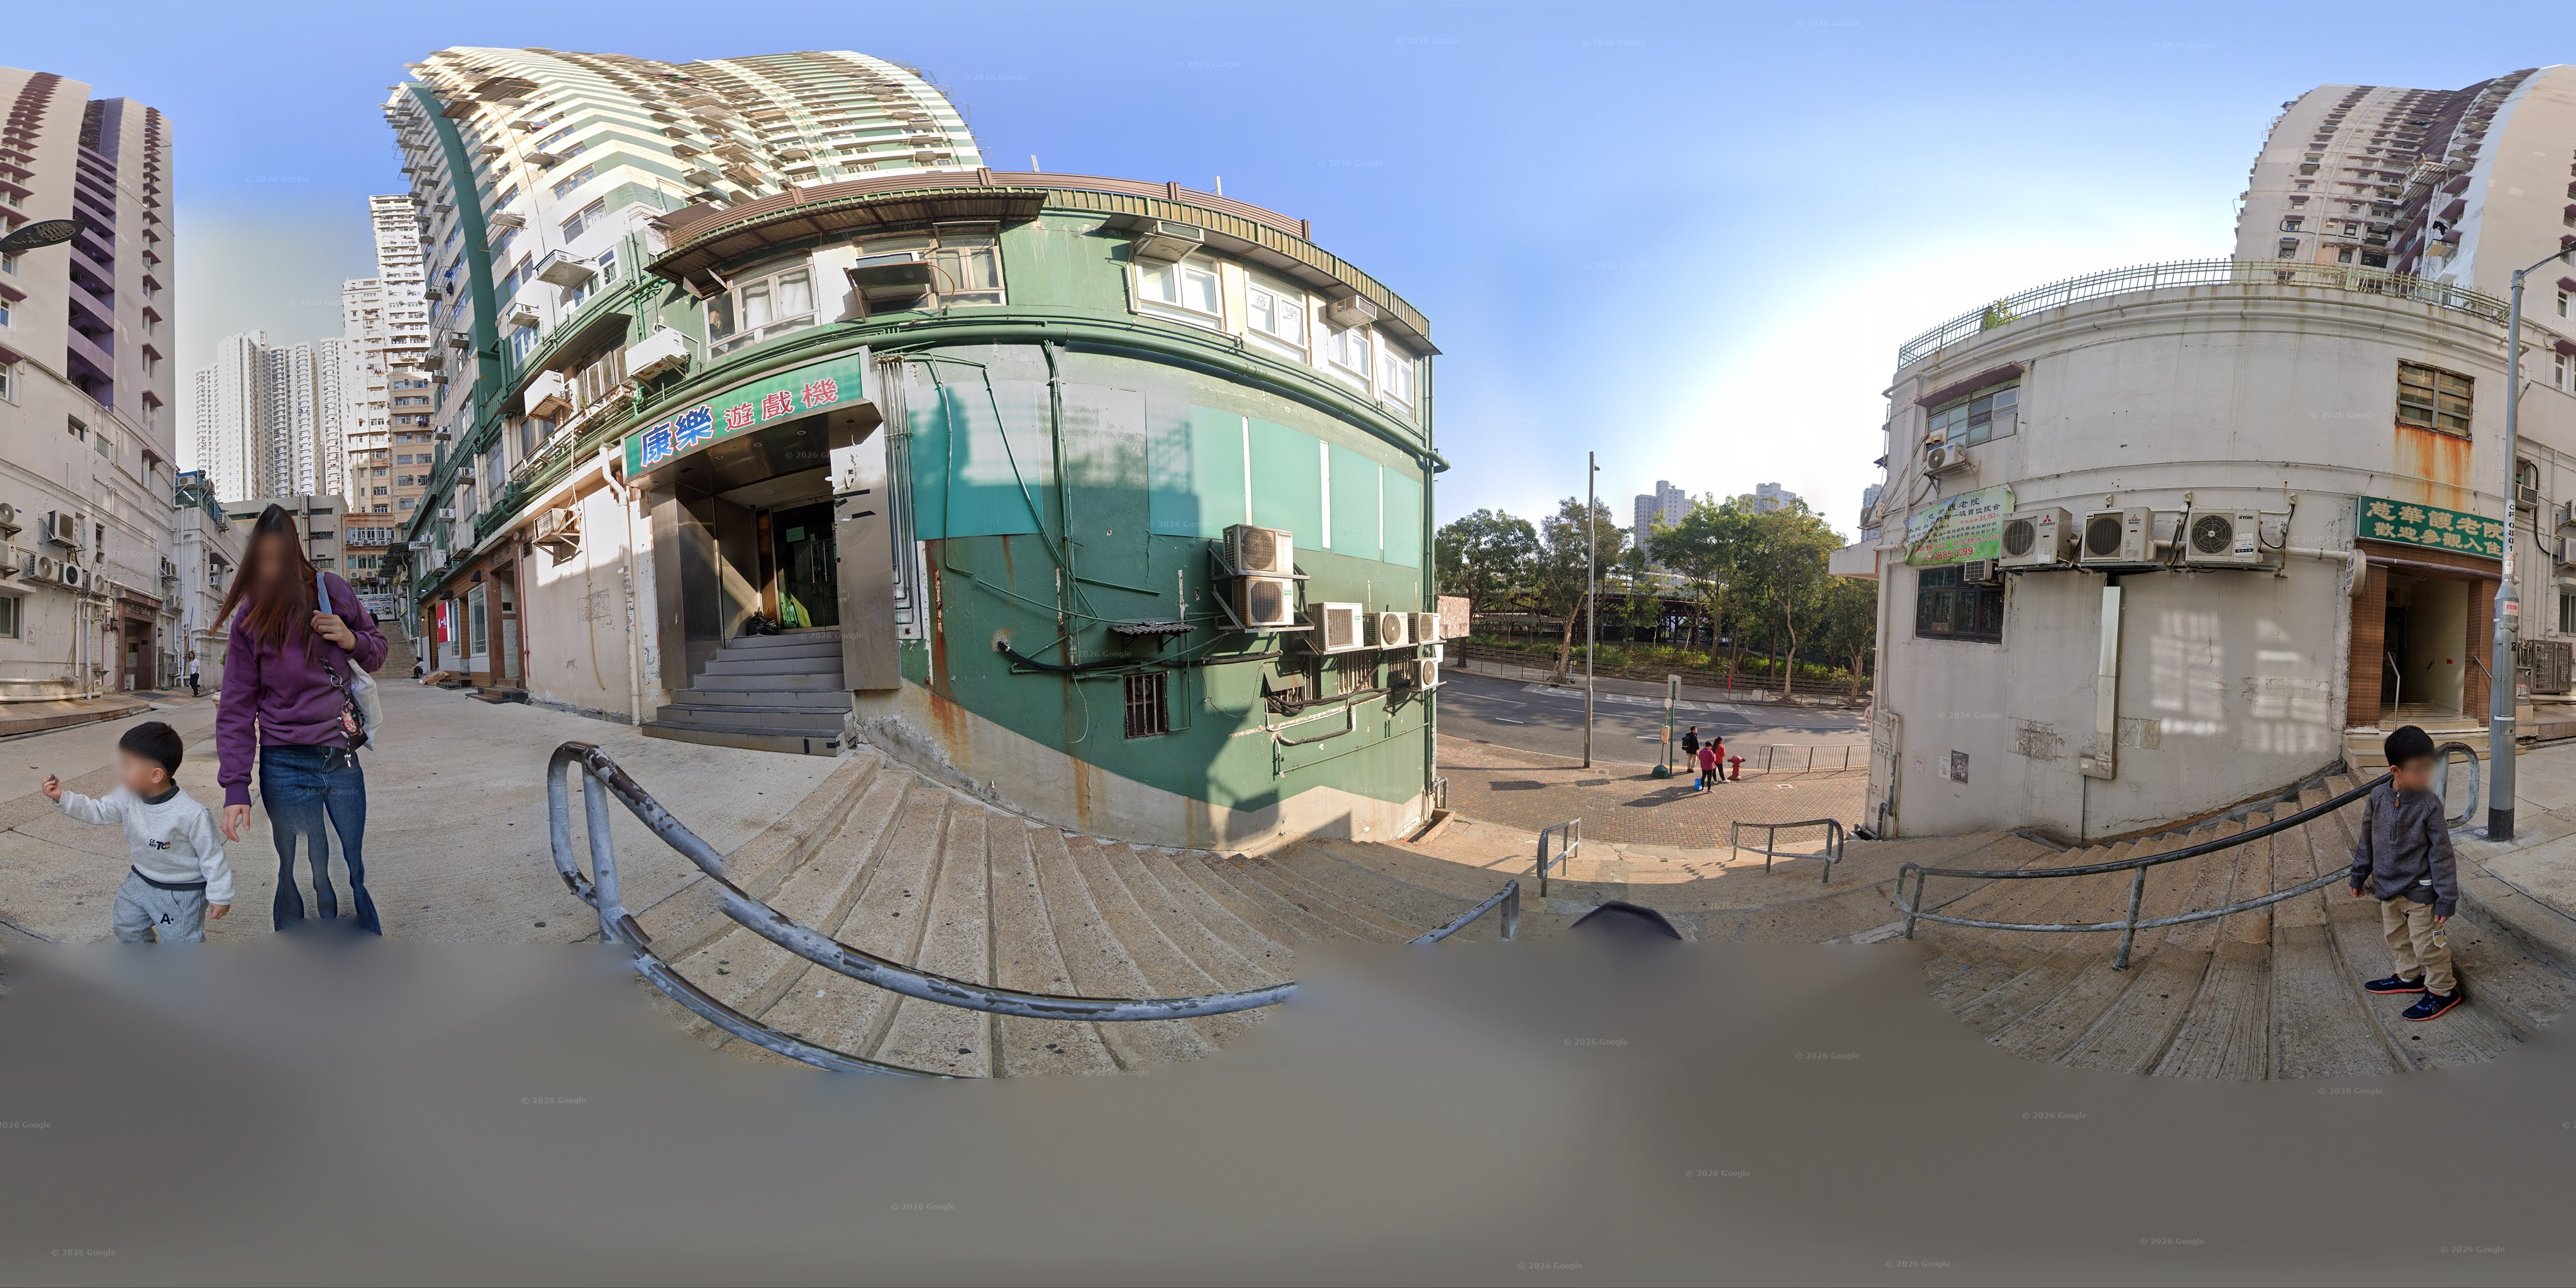

In [ ]:
from IPython.display import Image as IPImage, display

# Display the first picture
if os.path.exists(output):
    files = [f for f in os.listdir(output) if f.endswith('.jpg')]
    if files:
        first_image = os.path.join(output, files[0])  # here you can Modifiy the id number to check different images
        print(f"Visualizing image: {files[0]}")   # here you can Modifiy the id number to print the corresponding image name
        display(IPImage(filename=first_image, width=800))
    else:
        print("no image in this folder")
else:
    print("out is not exist")


**read_and_parse_image_filenames**

Summary:
Data Analysis Key Findings
A Pandas DataFrame was successfully generated, containing extracted metadata (ID, longitude, and latitude) from a collection of image filenames located in the specified directory.

Each row of the DataFrame represents a single image file, with its unique identifier and precise geographic coordinates (longitude and latitude) parsed from its filename.

In [ ]:
import pandas as pd
import os

# Define the directory where the image is located
image_directory = output # output The variable has been defined in the previous cell.

# Initialize a list to store the parsed data
data = []

# Check if the directory exists
if os.path.exists(image_directory):
    # Traverse all files in the directory
    for filename in os.listdir(image_directory):
        # Check if the file is in .jpg format
        if filename.endswith('.jpg'):
            # Remove the .jpg extension
            base_name = filename.replace('.jpg', '')

            # Split the file name by '_'
            parts = base_name.split('_')

            # Ensure that after disassembly, there are 3 parts (ID, longitude, latitude)
            if len(parts) == 3:
                image_id = parts[0]
                longitude = float(parts[1])
                latitude = float(parts[2])

                # Add the parsed data to the list.
                data.append({'Filename': filename, 'ID': image_id, 'Longitude': longitude, 'Latitude': latitude})

    # Create a Pandas DataFrame
    df = pd.DataFrame(data)

    # Display the first few rows of the DataFrame
    print("Successfully extracted information from file names and created a DataFrame：")
    display(df.head())
else:
    print(f"Error: Directory '{image_directory}' does not exist.")

Successfully extracted information from file names and created a DataFrame：


,Filename,ID,Longitude,Latitude
0,1_114.1986778_22.3432475.jpg,1,114.198678,22.343248
1,2_114.1984918_22.3421.jpg,2,114.198492,22.342100
2,3_114.1984177_22.34172778.jpg,3,114.198418,22.341728
3,4_114.1969273_22.34243581.jpg,4,114.196927,22.342436
4,5_114.1971951_22.34329821.jpg,5,114.197195,22.343298
